# Ingresos: cuantiles, bandas y cobertura por segmento

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Cobertura nominal:** 0.8
- **Cobertura test ampliada:** 0.7829
- **Cobertura con cambio de ingreso:** 0.2057
- **Ampliación en log puntos:** 0.0097

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Qué rango de ingreso es compatible con una actividad y cuánta incertidumbre conserva? Ajustamos cuantiles, ampliamos bandas con una calibración separada y distinguimos cobertura de detección de fraude.

### Supuestos y población

Ingreso mensual corroborado simulado, en COP. Mezcla de asalariados e independientes con ruido diferente. Entrenamiento, calibración y test son independientes y estacionarios por construcción; no se presupone intercambiabilidad de una cartera real.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Pérdida cuantílica y mecanismo generador


$$\rho_\tau(u)=u(\tau-\mathbf{1}_{u<0}),\quad \hat q_\tau(x)=\arg\min_f\sum_i\rho_\tau(y_i-f(x_i)).$$

Modelamos $y=\log(I)$ con $I>0$ y cuantiles 0,1 y 0,9 para una banda nominal 80%. La población del experimento no contiene ingresos cero; no extrapolar la transformación a ese caso sin un modelo aparte.

In [2]:
from sklearn.ensemble import GradientBoostingRegressor
n=2200
independent=rng.binomial(1,.4,n)
month=rng.integers(0,12,n)
activity=rng.uniform(0,1,n)
x=np.column_stack([activity,independent,np.sin(2*np.pi*month/12),np.cos(2*np.pi*month/12)])
mean=np.log(2_000_000)+.6*activity+.2*independent+.12*np.sin(2*np.pi*month/12)
y=mean+rng.normal(size=n)*(.12+.25*independent)
train,cal,test=np.arange(1000),np.arange(1000,1500),np.arange(1500,2200)
quantiles={tau:GradientBoostingRegressor(loss='quantile',alpha=tau,n_estimators=90,max_depth=2,random_state=21).fit(x[train],y[train]) for tau in [.1,.9]}
def bands(indices):
    a,b=quantiles[.1].predict(x[indices]),quantiles[.9].predict(x[indices])
    return np.minimum(a,b),np.maximum(a,b)
lo_cal,hi_cal=bands(cal);lo,hi=bands(test)
display(pd.DataFrame({'grupo':['asalariado','independiente'],'sigma_log':[.12,.37],'train_n':[(independent[train]==k).sum() for k in [0,1]]}))

,grupo,sigma_log,train_n
0,asalariado,0.1200,598
1,independiente,0.3700,402


El generador permite comprobar heterocedasticidad conocida. Ordenar los cuantiles elimina cruces en este ejercicio, pero no garantiza calibración ni aprende un modelo de fraude.

## 2. Ampliación conformal conservadora


Sobre la muestra de calibración: $s_i=\max(\hat q_{.1}(x_i)-y_i,y_i-\hat q_{.9}(x_i),0)$.

Sea $k=\lceil(n_{cal}+1)(1-\alpha)\rceil$ y $\hat s=s_{(k)}$. La banda ampliada es $[\hat q_{.1}-\hat s,\hat q_{.9}+\hat s]$. Se usa la variante conservadora con scores no negativos: solo amplía. El rango k debe existir; para niveles extremos se requiere una banda no acotada u otro tratamiento explícito.

,población,n,cobertura_original,cobertura_ampliada,ancho_medio_COP
0,Todos,700,0.7571,0.7829,"1,640,038.8948"
1,Asalariados,449,0.7728,0.8018,"911,268.5470"
2,Independientes,251,0.7291,0.7490,"2,943,695.8118"


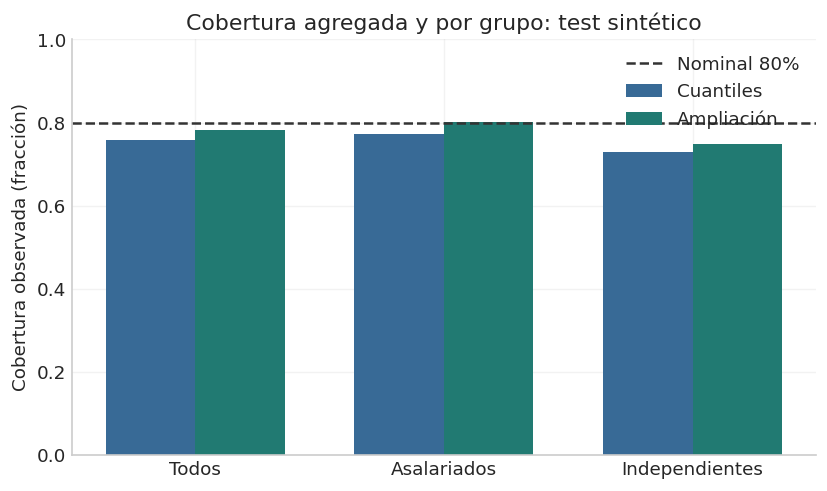

In [3]:
alpha=.2
scores=np.maximum.reduce([lo_cal-y[cal],y[cal]-hi_cal,np.zeros(len(cal))])
k=math.ceil((len(cal)+1)*(1-alpha))
assert k<=len(cal)
qhat=np.sort(scores)[k-1]
lo_c,hi_c=lo-qhat,hi+qhat
coverage_raw=((y[test]>=lo)&(y[test]<=hi))
coverage_c=((y[test]>=lo_c)&(y[test]<=hi_c))
coverage_table=[]
for label,mask in [('Todos',np.ones(len(test),bool)),('Asalariados',independent[test]==0),('Independientes',independent[test]==1)]:
    coverage_table.append({'población':label,'n':int(mask.sum()),'cobertura_original':coverage_raw[mask].mean(),'cobertura_ampliada':coverage_c[mask].mean(),'ancho_medio_COP':np.mean(np.exp(hi_c[mask])-np.exp(lo_c[mask]))})
coverage_table=pd.DataFrame(coverage_table);display(coverage_table)
fig,ax=plt.subplots();positions=np.arange(3)
ax.bar(positions-.18,coverage_table['cobertura_original'],width=.36,label='Cuantiles',color=BLUE)
ax.bar(positions+.18,coverage_table['cobertura_ampliada'],width=.36,label='Ampliación',color=TEAL)
ax.axhline(.8,linestyle='--',color='#333333',label='Nominal 80%');ax.set_xticks(positions,coverage_table['población'])
ax.set(ylim=(0,1),ylabel='Cobertura observada (fracción)',title='Cobertura agregada y por grupo: test sintético');ax.legend();plt.show()

La garantía marginal de la construcción requiere intercambiabilidad; no promete cobertura en cada segmento. La tabla muestra grupo, tamaño y ancho. Conservar grupos con peor cobertura aunque el agregado esté cerca de 80%.

## 3. Bandas en moneda y cambio de distribución


La exponencial es monótona: la banda de log ingreso puede transformarse a COP. Después se desplaza solo el ingreso de prueba en 0,4 log puntos, manteniendo la banda congelada: se viola el mecanismo estacionario de calibración.

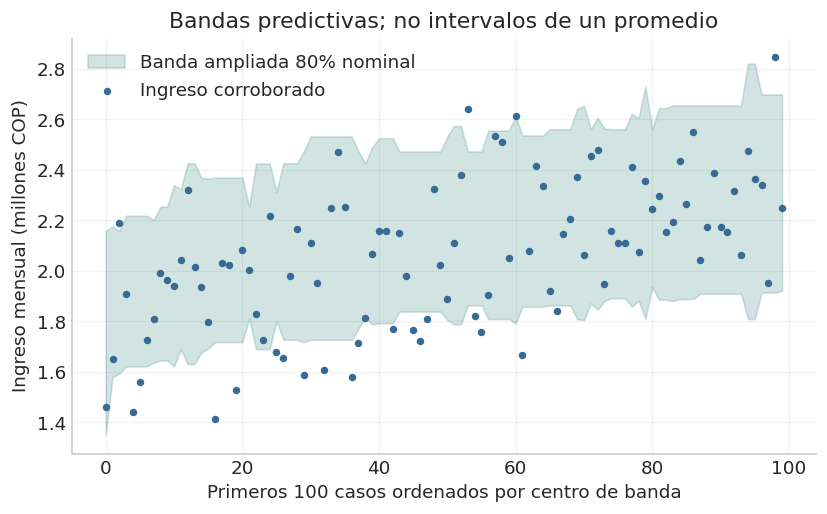

,escenario,cobertura
0,Estacionario,0.7829
1,"Desplazamiento +0,4 log",0.2057


In [4]:
order=np.argsort((lo_c+hi_c)/2)[:100]
fig,ax=plt.subplots();axis=np.arange(len(order))
ax.fill_between(axis,np.exp(lo_c[order])/1e6,np.exp(hi_c[order])/1e6,color=TEAL,alpha=.2,label='Banda ampliada 80% nominal')
ax.scatter(axis,np.exp(y[test][order])/1e6,s=12,color=BLUE,label='Ingreso corroborado')
ax.set(xlabel='Primeros 100 casos ordenados por centro de banda',ylabel='Ingreso mensual (millones COP)',title='Bandas predictivas; no intervalos de un promedio');ax.legend();plt.show()
shifted=y[test]+.4
shift_coverage=((shifted>=lo_c)&(shifted<=hi_c)).mean()
display(pd.DataFrame({'escenario':['Estacionario','Desplazamiento +0,4 log'],'cobertura':[coverage_c.mean(),shift_coverage]}))

La banda describe un ingreso corroborado hipotético, no la honestidad de una declaración. Una declaración fuera de banda puede motivar aclaración; no confirma fraude. La sensibilidad bajo cambio de distribución conserva un fallo potencial de cobertura.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert qhat>=0
assert np.all(lo_c<=hi_c)
assert coverage_c.mean()>=coverage_raw.mean()
assert shift_coverage<coverage_c.mean()

## Resultados computados

In [6]:
metrics = {'Cobertura nominal': .8, 'Cobertura test ampliada': round(float(coverage_c.mean()),4), 'Cobertura con cambio de ingreso': round(float(shift_coverage),4), 'Ampliación en log puntos': round(float(qhat),4)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Cobertura nominal": 0.8, "Cobertura test ampliada": 0.7829, "Cobertura con cambio de ingreso": 0.2057, "Ampliación en log puntos": 0.0097}


## Ideas y preguntas para continuar

1. Comparar calibración marginal y por segmento, con tamaños mínimos.
2. Incorporar ingresos cero mediante un modelo en dos partes.
3. Tratar períodos faltantes como cobertura de evidencia y no ingreso cero.
4. Diseñar indicadores de cambio de régimen antes de recalibrar.
5. Separar discrepancia de ingreso de tergiversación adjudicada.

## Fuentes y relación con el proyecto

- [Romano, Patterson y Candès: Conformalized Quantile Regression](https://arxiv.org/abs/1905.03222).
- [scikit-learn: regresión cuantílica con boosting](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html).

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.